# 09 — Classifier ensemble (Logistic Regression + Linear SVM + RBF SVM + Random Forest)

Combines the **saved validation/test outputs** of your classifiers (`saved_models/*_val_probs.npy`, `*_test_probs.npy`) — no retraining.

Ensembles compared: equal-weight soft voting, **weighted soft voting** (weights searched on validation), hard majority voting, and **stacking** (logistic-regression meta-model, cross-validated on validation).
Everything is chosen on **validation only**; **test** is touched once for the final report.

Runs on CPU in seconds — Colab **CPU runtime** is fine (no GPU needed), or locally.

In [1]:
# ============================================================
# 1. Paths + load labels, splits and every model's saved outputs
# ============================================================
import sys, os, json, itertools, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
PROJECT_DIR = (Path("/content/drive/MyDrive/AI_Image_Project") if IN_COLAB
               else Path(os.environ.get("AI_PROJECT_DIR", r"C:\AI_Image_Project")))   # <- laptop folder
FEATURES_DIR, MODELS_DIR = PROJECT_DIR / "features", PROJECT_DIR / "saved_models"
OUT_DIR = PROJECT_DIR / "results" / "ensemble"; OUT_DIR.mkdir(parents=True, exist_ok=True)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

y_all = np.load(FEATURES_DIR / "y_labels_15k.npy", allow_pickle=True)
def load_split(name):
    p = FEATURES_DIR / f"{name}_idx.npy"
    if p.exists(): return np.load(p)
    return np.load(FEATURES_DIR / "split_indices.npz")[f"{name}_idx"]
val_idx, test_idx = load_split("val"), load_split("test")
classes = np.unique(y_all); K = len(classes)
y_val = np.searchsorted(classes, y_all[val_idx]); y_test = np.searchsorted(classes, y_all[test_idx])

# Human-readable class names from the image folders, if the path list is available
class_names = [f"class {c}" for c in classes]
paths_file = FEATURES_DIR / "image_paths_15k.npy"
paths_all = np.load(paths_file, allow_pickle=True) if paths_file.exists() else None
if paths_all is not None and len(paths_all) == len(y_all):
    folder = pd.Series([Path(str(p)).parent.name for p in paths_all])
    nice = {"COCO_5000": "Real (COCO)", "DiffusionDB_5000": "Full AI (DiffusionDB)", "Partial_AI_5000": "Partial AI",
            "Manipulated": "Partial AI"}
    class_names = [nice.get(folder[y_all == c].mode().iloc[0], folder[y_all == c].mode().iloc[0]) for c in classes]
print("Classes:", dict(zip(classes.tolist(), class_names)))
print(f"Validation: {len(val_idx)} | Test: {len(test_idx)}")

# Discover every model that has both val and test outputs
NICE_MODEL = {"logreg": "Logistic Regression", "svm": "Linear SVM", "svm_rbf": "RBF SVM", "rf_scratch": "Random Forest"}
raw = {}
for vf in sorted(MODELS_DIR.glob("*_val_probs.npy")):
    key = vf.name[: -len("_val_probs.npy")]
    tf = MODELS_DIR / f"{key}_test_probs.npy"
    if not tf.exists(): continue
    v, t = np.load(vf, allow_pickle=True).astype(float), np.load(tf, allow_pickle=True).astype(float)
    if len(v) != len(val_idx) or len(t) != len(test_idx):
        print(f"SKIP {key}: {len(v)} val / {len(t)} test rows, expected {len(val_idx)} / {len(test_idx)}"); continue
    raw[NICE_MODEL.get(key, key)] = (v, t)
assert len(raw) >= 2, f"Need at least 2 models with matching val/test outputs in {MODELS_DIR}"
print("Models:", list(raw))

Classes: {0: 'Real (COCO)', 1: 'Full AI (DiffusionDB)', 2: 'Partial AI'}
Validation: 1500 | Test: 1500
Models: ['Logistic Regression', 'Random Forest', 'RBF SVM', 'Linear SVM']


In [2]:
# ============================================================
# 2. Put every model on the same footing: calibrated class probabilities (n, K)
#    - real probabilities are used as-is
#    - raw scores (e.g. SVM decision values) are calibrated with a logistic model fitted on validation
#      (cross-validated on validation, so validation numbers stay honest)
# ============================================================
groups_val = None
if paths_all is not None and len(paths_all) == len(y_all):
    # group the 3 Flux variants of the same source image together (prefix before the first "_")
    groups_val = np.array([Path(str(p)).stem.split("_")[0] for p in paths_all[val_idx]])

def cv_splits(n_splits=5):
    if groups_val is not None and len(np.unique(groups_val)) >= n_splits:
        return list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=42).split(np.zeros(len(y_val)), y_val, groups_val))
    return list(StratifiedKFold(n_splits, shuffle=True, random_state=42).split(np.zeros(len(y_val)), y_val))
SPLITS = cv_splits()

def as_matrix(a):
    a = np.asarray(a, float)
    return a[:, None] if a.ndim == 1 else a

def looks_like_proba(a):
    if a.min() < -1e-6 or a.max() > 1 + 1e-6: return False
    return a.shape[1] == 1 or np.allclose(a.sum(1), 1, atol=1e-3)

def fit_cv_predict(make, Xv, yv, Xt):
    # out-of-fold predictions on validation + model fitted on all validation applied to test
    pv = np.zeros((len(yv), K))
    for tr, te in SPLITS:
        m = make().fit(Xv[tr], yv[tr])
        pv[np.ix_(te, m.classes_)] = m.predict_proba(Xv[te])
    m = make().fit(Xv, yv)
    pt = np.zeros((len(Xt), K)); pt[:, m.classes_] = m.predict_proba(Xt)
    return pv, pt

P_val, P_test, how = {}, {}, {}
for name, (v, t) in raw.items():
    v, t = as_matrix(v), as_matrix(t)
    if looks_like_proba(v) and looks_like_proba(t) and v.shape[1] in (1, K):
        if v.shape[1] == 1:                      # binary: column = P(class 1)
            v, t = np.hstack([1 - v, v]), np.hstack([1 - t, t])
        P_val[name], P_test[name], how[name] = v, t, "probabilities (as saved)"
    else:
        P_val[name], P_test[name] = fit_cv_predict(lambda: LogisticRegression(C=1.0, max_iter=2000), v, y_val, t)
        how[name] = f"scores {v.shape} -> calibrated on validation"
    P_val[name] = np.clip(P_val[name], 1e-7, 1); P_val[name] /= P_val[name].sum(1, keepdims=True)
    P_test[name] = np.clip(P_test[name], 1e-7, 1); P_test[name] /= P_test[name].sum(1, keepdims=True)
for n in P_val: print(f"{n:22s}: {how[n]}")
MODELS = list(P_val)

Logistic Regression   : probabilities (as saved)
Random Forest         : probabilities (as saved)
RBF SVM               : probabilities (as saved)
Linear SVM            : probabilities (as saved)


In [3]:
# ============================================================
# 3. Ensembles (all settings chosen on validation)
# ============================================================
def metrics(p, y):
    pred = p.argmax(1)
    out = {"Accuracy": accuracy_score(y, pred), "Balanced_acc": balanced_accuracy_score(y, pred),
           "Macro_F1": f1_score(y, pred, average="macro"), "Log_loss": log_loss(y, p, labels=range(K))}
    try:
        out["AUC"] = roc_auc_score(y, p[:, 1]) if K == 2 else roc_auc_score(y, p, multi_class="ovr", average="macro")
    except ValueError:
        out["AUC"] = np.nan
    return out

V = np.stack([P_val[m] for m in MODELS]); T = np.stack([P_test[m] for m in MODELS])   # (M, n, K)
results = {}   # name -> (val_probs, test_probs, description)
for i, m in enumerate(MODELS):
    results[m] = (V[i], T[i], "single model")

# (a) equal-weight soft voting
results["Soft voting (equal)"] = (V.mean(0), T.mean(0), "mean of probabilities")

# (b) weighted soft voting: grid over the weight simplex (step 0.1), best validation macro-F1, log-loss as tie-break
step = 10
grid = [np.array(w) / step for w in itertools.product(range(step + 1), repeat=len(MODELS)) if sum(w) == step]
def score_w(w):
    p = np.tensordot(w, V, 1)
    return (f1_score(y_val, p.argmax(1), average="macro"), -log_loss(y_val, p, labels=range(K)))
best_w = max(grid, key=score_w)
results["Soft voting (weighted)"] = (np.tensordot(best_w, V, 1), np.tensordot(best_w, T, 1),
                                     "weights " + ", ".join(f"{m}={w:.1f}" for m, w in zip(MODELS, best_w)))

# (c) hard majority voting (ties broken by the mean probability)
def hard_vote(P):
    votes = np.zeros(P.shape[1:])
    for p in P: votes[np.arange(len(p)), p.argmax(1)] += 1
    return (votes + 1e-3 * P.mean(0)) / (votes + 1e-3 * P.mean(0)).sum(1, keepdims=True)
results["Hard majority voting"] = (hard_vote(V), hard_vote(T), "one vote per model")

# (d) stacking: logistic regression on the log-probabilities of all models
Xv = np.log(np.concatenate([P_val[m] for m in MODELS], 1)); Xt = np.log(np.concatenate([P_test[m] for m in MODELS], 1))
sv, st = fit_cv_predict(lambda: LogisticRegression(C=0.5, max_iter=5000), Xv, y_val, Xt)
results["Stacking (LogReg meta-model)"] = (sv, st, "meta-model trained on validation (5-fold CV for val score)")

rows = []
for name, (pv, pt, desc) in results.items():
    rows.append({"Model": name, "Split": "Validation", **metrics(pv, y_val)})
    rows.append({"Model": name, "Split": "Test", **metrics(pt, y_test)})
table = pd.DataFrame(rows)
val_rank = table[table.Split == "Validation"].sort_values(["Macro_F1", "Log_loss"], ascending=[False, True])
BEST = val_rank.iloc[0]["Model"]
best_single = val_rank[val_rank.Model.isin(MODELS)].iloc[0]["Model"]

test_table = table[table.Split == "Test"].set_index("Model").drop(columns="Split")
test_table["chosen_on_val"] = ["<- BEST" if m == BEST else "" for m in test_table.index]
print("Weighted voting:", results["Soft voting (weighted)"][2])
print(f"\nSelected on validation: {BEST}   (best single model on validation: {best_single})\n")
print("TEST results (each model/ensemble evaluated once):")
display(test_table.round(4)) if "display" in globals() else print(test_table.round(4))

Weighted voting: weights Logistic Regression=0.4, Random Forest=0.4, RBF SVM=0.2, Linear SVM=0.0

Selected on validation: Stacking (LogReg meta-model)   (best single model on validation: Logistic Regression)

TEST results (each model/ensemble evaluated once):
                              Accuracy  Balanced_acc  Macro_F1  Log_loss     AUC chosen_on_val
Model                                                                                         
Logistic Regression             0.8080        0.8080    0.8077    0.4124  0.9304              
Random Forest                   0.7967        0.7967    0.7972    0.5007  0.9264              
RBF SVM                         0.7440        0.7440    0.7323    0.8680  0.8983              
Linear SVM                      0.8100        0.8100    0.8084    0.4503  0.9272              
Soft voting (equal)             0.8233        0.8233    0.8216    0.5061  0.9393              
Soft voting (weighted)          0.8273        0.8273    0.8262    0.4840  0

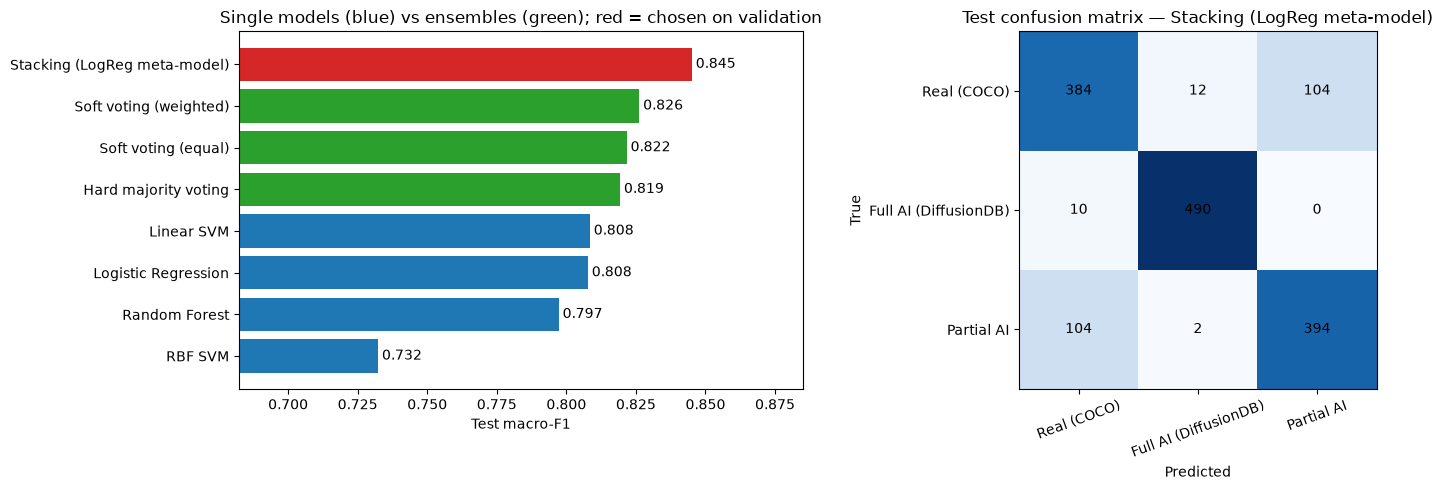

Per-class report on TEST — Stacking (LogReg meta-model)
                       precision    recall  f1-score   support

          Real (COCO)     0.7711    0.7680    0.7695       500
Full AI (DiffusionDB)     0.9722    0.9800    0.9761       500
           Partial AI     0.7912    0.7880    0.7896       500

             accuracy                         0.8453      1500
            macro avg     0.8448    0.8453    0.8451      1500
         weighted avg     0.8448    0.8453    0.8451      1500

Saved to C:\AI_Image_Project\results\ensemble


In [4]:
# ============================================================
# 4. Plots, per-class report, save
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
tt = test_table.sort_values("Macro_F1")
ax[0].barh(tt.index, tt["Macro_F1"], color=["#d62728" if m == BEST else ("#1f77b4" if m in MODELS else "#2ca02c") for m in tt.index])
for i, v in enumerate(tt["Macro_F1"]): ax[0].text(v, i, f" {v:.3f}", va="center")
ax[0].set_xlim(max(0, tt["Macro_F1"].min() - 0.05), min(1, tt["Macro_F1"].max() + 0.04))
ax[0].set_xlabel("Test macro-F1"); ax[0].set_title("Single models (blue) vs ensembles (green); red = chosen on validation")

cm = confusion_matrix(y_test, results[BEST][1].argmax(1), labels=range(K))
ax[1].imshow(cm, cmap="Blues")
ax[1].set_xticks(range(K), class_names, rotation=20); ax[1].set_yticks(range(K), class_names)
for (r, c), v in np.ndenumerate(cm): ax[1].text(c, r, v, ha="center", va="center")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True"); ax[1].set_title(f"Test confusion matrix — {BEST}")
plt.tight_layout(); plt.savefig(OUT_DIR / "classifier_ensemble_test.png", dpi=120); plt.show()

print(f"Per-class report on TEST — {BEST}")
print(classification_report(y_test, results[BEST][1].argmax(1), labels=range(K), target_names=class_names, digits=4))

table.to_csv(OUT_DIR / "classifier_ensemble_comparison.csv", index=False)
np.save(OUT_DIR / "ensemble_val_probs.npy", results[BEST][0]); np.save(OUT_DIR / "ensemble_test_probs.npy", results[BEST][1])
json.dump({"selected": BEST, "selected_by": "validation macro-F1 (log-loss tie-break)",
           "weighted_voting": dict(zip(MODELS, best_w.round(2).tolist())), "inputs": how,
           "test_metrics": {k: float(v) for k, v in test_table.loc[BEST].drop("chosen_on_val").items()}},
          open(OUT_DIR / "classifier_ensemble_summary.json", "w"), indent=2)
print("Saved to", OUT_DIR)